# Lab 1

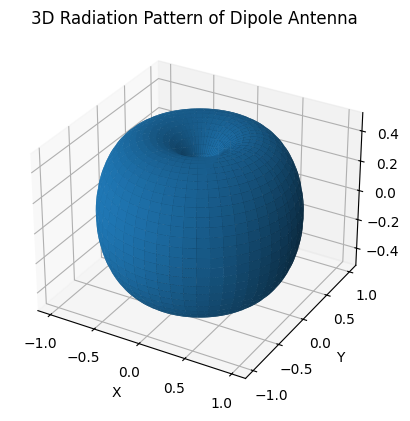

In [3]:
# Dipole Antenna - 3D Radiation Pattern  of dipole antenna 

import numpy as np
import matplotlib.pyplot as plt

# Angle values
theta = np.linspace(0, np.pi, 100)
phi = np.linspace(0, 2 * np.pi, 100)

theta, phi = np.meshgrid(theta, phi)

# Radiation pattern
R = np.abs(np.sin(theta))

# Coordinate conversion
X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

# Plot
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.plot_surface(X, Y, Z)

ax.set_title("3D Radiation Pattern of Dipole Antenna")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

# Lab 2

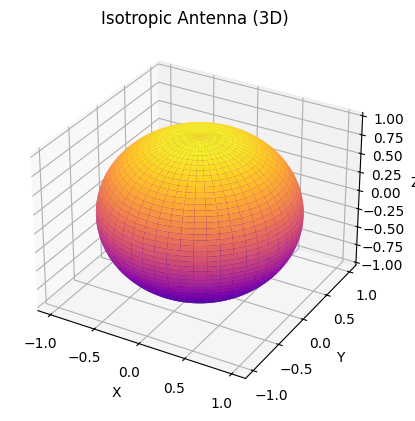

In [23]:
# Isotropic Antenna - 3D Radiation Pattern isotropic antenna

import numpy as np
import matplotlib.pyplot as plt

# Angle values
theta = np.linspace(0, np.pi, 200)
phi = np.linspace(0, 2 * np.pi, 200)

theta, phi = np.meshgrid(theta, phi)

# Radiation pattern
#R = np.abs(np.cos(theta))
R = 1   #fixed

# Coordinate conversion
X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

# Plot
ax = plt.figure().add_subplot(projection='3d')

ax.plot_surface(X, Y, Z, cmap="plasma")

ax.set_title("Isotropic Antenna (3D)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

# Lab3

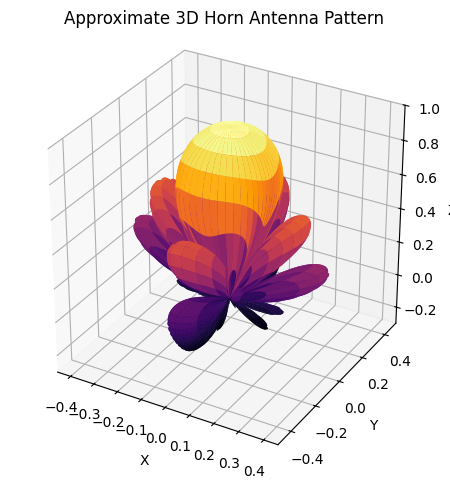

In [1]:
import numpy as np
import matplotlib.pyplot as plt
theta = np.linspace(0, np.pi, 220)
phi = np.linspace(0, 2*np.pi, 240)
TH, PH = np.meshgrid(theta, phi)
u = 10*np.sin(TH)*np.cos(PH)      # 3 -> 10 (aperture boro, beam narrow)
v = 8*np.sin(TH)*np.sin(PH)       # 2 -> 8
E = np.abs(np.sinc(u/np.pi) * np.sinc(v/np.pi)) * (1 + np.cos(TH))/2   # back radiation komano
E = E / E.max()
E = np.maximum(20*np.log10(np.maximum(E, 1e-6)), -40)   # dB scale
E = (E + 40) / 40                                       # 0..1 e normalize
X = E*np.sin(TH)*np.cos(PH)
Y = E*np.sin(TH)*np.sin(PH)
Z = E*np.cos(TH)
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="inferno", linewidth=0)
ax.set_title("Approximate 3D Horn Antenna Pattern")
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_box_aspect((1, 1, 1))
ax.set_zlim(-0.3, 1)
plt.tight_layout()
plt.show()

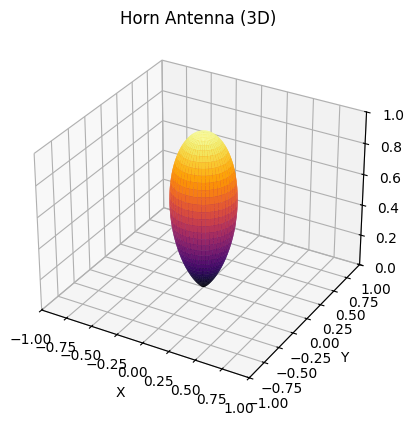

In [38]:
# Horn Antenna - 3D
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, np.pi/2, 250)    
phi = np.linspace(0, 2*np.pi, 250)
theta, phi = np.meshgrid(theta, phi)

n = 4
R = np.cos(theta)**n                    

X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(X, Y, Z, cmap="inferno")
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_zlim(0, 1)
ax.set_title("Horn Antenna (3D)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

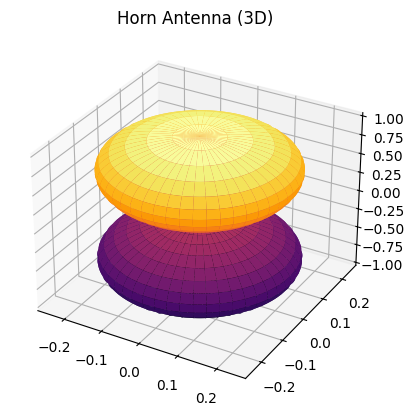

In [4]:
#Lab-3: Study and Simulation of the 3D Radiation Pattern of a Horn Antenna 
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, np.pi, 250)
phi = np.linspace(0, 2*np.pi, 250)
theta, phi = np.meshgrid(theta, phi)

n = 6
R = np.abs(np.cos(theta))**n

X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

ax = plt.figure().add_subplot(projection='3d')
ax.plot_surface(X, Y, Z, cmap="inferno")
ax.set_title("Horn Antenna (3D)")
plt.show()


# Lab 4

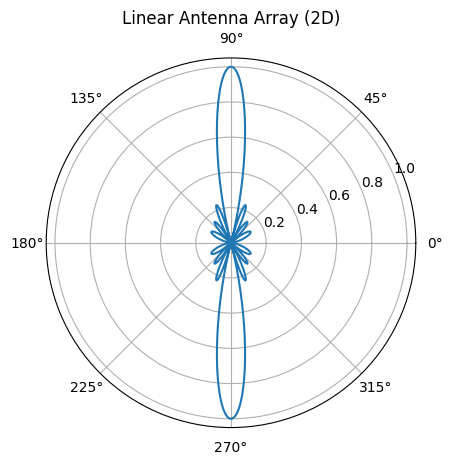

In [5]:
# Linear Antenna Array - 2D Radiation Pattern

import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 8                 # Number of elements
d = 0.5               # Spacing (lambda / 2)
k = 2 * np.pi         # Wave number
beta = 0              # Phase difference

# Angle
theta = np.linspace(0, 2 * np.pi, 1000)

# Array Factor
AF = np.zeros_like(theta, dtype=complex)

for n in range(N):
    AF += np.exp(1j * n * (k * d * np.cos(theta) + beta))

# Magnitude
AF = np.abs(AF)

# Normalize
AF = AF / np.max(AF)

# Plot
ax = plt.subplot(111, projection="polar")
ax.plot(theta, AF)

ax.set_title("Linear Antenna Array (2D)")

plt.show()

# Lab 5

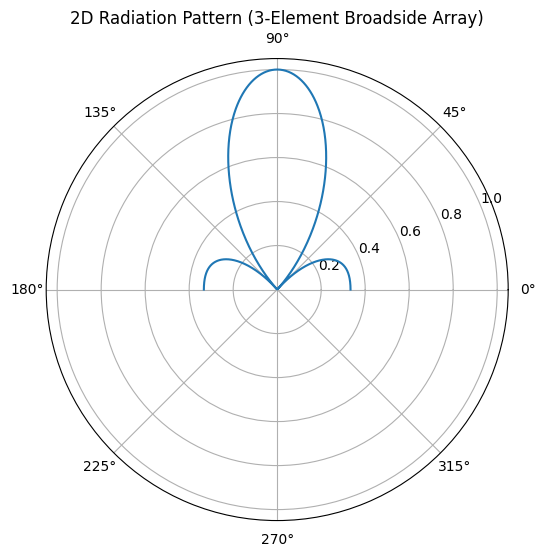

In [6]:
# Broadside Array Antenna (3-Element)

import numpy as np
import matplotlib.pyplot as plt

# Parameters
lam = 1
d = lam / 2
k = 2 * np.pi / lam
N = 3                 # Number of elements

# Angle range
theta = np.linspace(0, np.pi, 1000)

# Array Factor
AF = np.zeros_like(theta, dtype=complex)

for n in range(N):
    AF += np.exp(1j * n * k * d * np.cos(theta))

# Normalize
AF_mag = np.abs(AF)
AF_mag = AF_mag / np.max(AF_mag)

# Plot
plt.figure(figsize=(6, 6))

ax = plt.subplot(111, projection='polar')
ax.plot(theta, AF_mag)

ax.set_title("2D Radiation Pattern (3-Element Broadside Array)")

plt.show()

# Lab 6

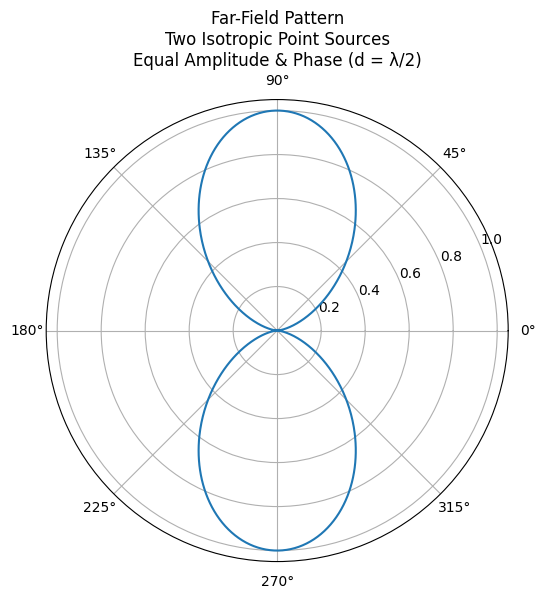

In [1]:
# Two Isotropic Point Sources
# Equal Amplitude & Phase

import numpy as np
import matplotlib.pyplot as plt

# Parameters
lam = 1.0
d = lam / 2
k = 2 * np.pi / lam

# Angle range
theta = np.linspace(0, 2 * np.pi, 1000)

# Array Factor
AF = 2 * np.cos((k * d / 2) * np.cos(theta))

# Normalize
AF_norm = np.abs(AF) / np.max(np.abs(AF))

# Plot
plt.figure(figsize=(6, 6))

plt.polar(theta, AF_norm)

plt.title(
    "Far-Field Pattern\n"
    "Two Isotropic Point Sources\n"
    "Equal Amplitude & Phase (d = λ/2)"
)

plt.show()

# Lab 7

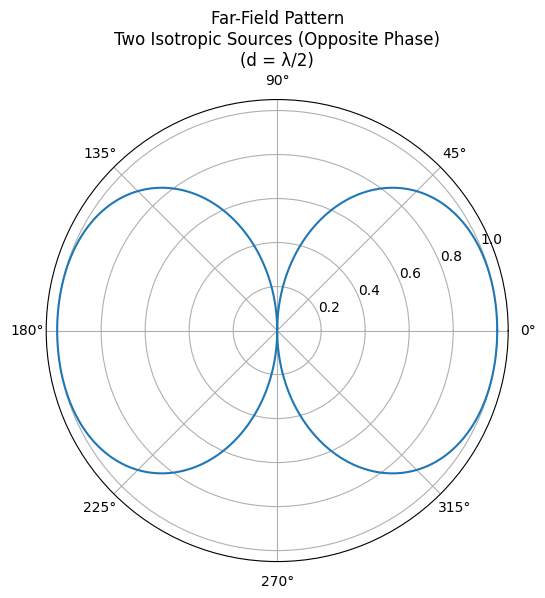

In [2]:
# Two Isotropic Point Sources
# Opposite Phase

import numpy as np
import matplotlib.pyplot as plt

# Parameters
lam = 1.0
d = lam / 2
k = 2 * np.pi / lam

# Angle range
theta = np.linspace(0, 2 * np.pi, 1000)

# Array Factor (Opposite Phase)
AF = 2 * np.sin((k * d / 2) * np.cos(theta))

# Normalize
AF_norm = np.abs(AF) / np.max(np.abs(AF))

# Plot
plt.figure(figsize=(6, 6))

plt.polar(theta, AF_norm)

plt.title(
    "Far-Field Pattern\n"
    "Two Isotropic Sources (Opposite Phase)\n"
    "(d = λ/2)"
)

plt.show()

# Lab 8

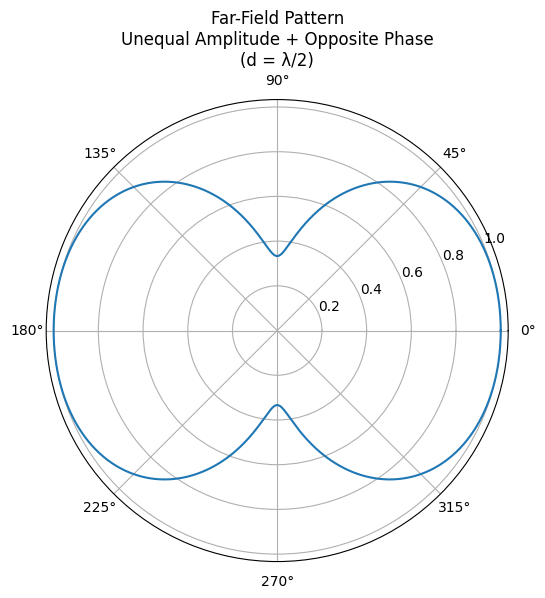

In [3]:
# Two Isotropic Sources
# Unequal Amplitude + Opposite Phase

import numpy as np
import matplotlib.pyplot as plt

# Parameters
lam = 1.0
d = lam / 2
k = 2 * np.pi / lam

# Amplitude weights
A1 = 1
A2 = 0.5                 # Unequal amplitude

# Angle range
theta = np.linspace(0, 2 * np.pi, 1000)

# Array Factor
AF = A1 - A2 * np.exp(1j * k * d * np.cos(theta))

# Normalize
AF_norm = np.abs(AF) / np.max(np.abs(AF))

# Plot
plt.figure(figsize=(6, 6))

plt.polar(theta, AF_norm)

plt.title(
    "Far-Field Pattern\n"
    "Unequal Amplitude + Opposite Phase\n"
    "(d = λ/2)"
)

plt.show()

# Lab 9

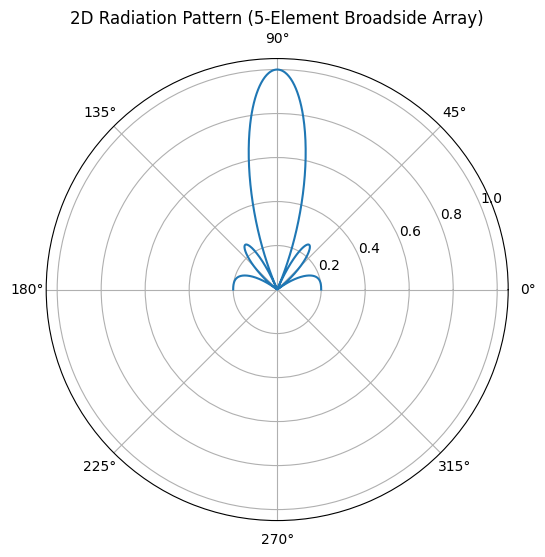

In [6]:
# Broadside Array Antenna (5-Element)

import numpy as np
import matplotlib.pyplot as plt

# Parameters
lam = 1
d = lam / 2
k = 2 * np.pi / lam
N = 5                 # Number of elements

# Angle range
theta = np.linspace(0, np.pi, 1000)

# Array Factor
AF = np.zeros_like(theta, dtype=complex)

for n in range(N):
    AF += np.exp(1j * n * k * d * np.cos(theta))

# Normalize
AF_mag = np.abs(AF)
AF_mag = AF_mag / np.max(AF_mag)

# Plot
plt.figure(figsize=(6, 6))

ax = plt.subplot(111, projection='polar')
ax.plot(theta, AF_mag)

ax.set_title("2D Radiation Pattern (5-Element Broadside Array)")

plt.show()

# Lab 10

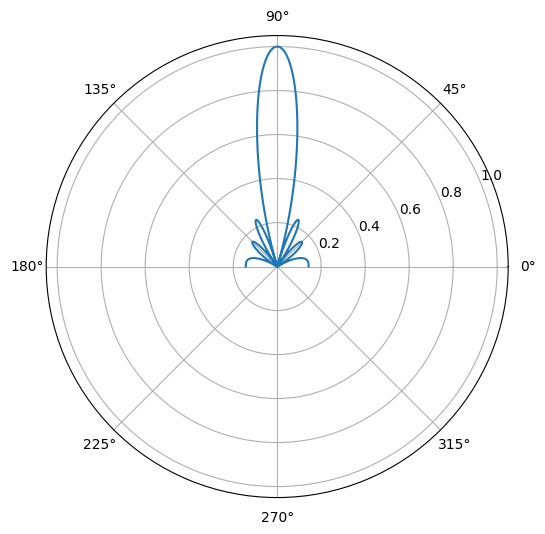

In [17]:
import numpy as np
import matplotlib.pyplot as plt

lam = 1
d = lam/2
k = 2* np.pi / lam
N = 7

theta = np.linspace(0, np.pi, 1000)

AF = np.zeros_like(theta, dtype=complex)

for n in range(N):
    AF += np.exp(1j * n * k * d * np.cos(theta))

AF_mag = np.abs(AF)

AF_mag = AF_mag/np.max(AF_mag)

plt.figure(figsize=(6,6))

ax = plt.subplot(111, projection='polar')

ax.plot(theta, AF_mag)

plt.show()